# Pemodelan Indeks Resiliensi Ekonomi 38 Provinsi Indonesia dengan Regresi Nonparametrik Spline Truncated

## **Install Library**

In [1]:
!pip install pandas numpy matplotlib seaborn scipy statsmodels openpyxl -q

## **Import Library**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from scipy.stats import kstest
from scipy.stats import norm
from scipy.stats import f
from statsmodels.sandbox.stats.runs import runstest_1samp

plt.rcParams["figure.figsize"] = (8,5)

## **Upload File**

In [3]:
from google.colab import files

uploaded = files.upload()

Saving data_pembentuk_indeks.xlsx to data_pembentuk_indeks.xlsx


## **Baca Data Pembentuk Indeks**

In [4]:
# File ini berisi 9 variabel pembentuk indeks komposit

df_index = pd.read_excel("/content/data_pembentuk_indeks.xlsx")

print(df_index.head())

         Provinsi  Inflasi  PDRB_Lapangan_Usaha  PDRB_per_Kapita  \
0            Aceh     2.17               243202         43782.22   
1  Sumatera Utara     2.12              1146920         73574.62   
2  Sumatera Barat     0.89               333146         57083.09   
3            Riau     1.25              1112482        165349.71   
4           Jambi     1.43               323174         86774.89   

   Penanaman_Modal    IPM   TPT    IDI  Kapasitas_Fiskal      KPM  
0           8317.0  75.36  5.75  75.80             28.31  1932814  
1          22445.7  75.76  5.60  80.19             55.67  3074198  
2           7956.3  76.43  5.75  78.83             45.39  1273639  
3          61097.6  75.67  3.70  77.06             57.18  1052412  
4           9986.2  74.36  4.48  82.27             44.21   684629  


## **Cek Nama Kolom Data Pembentuk Indeks**

In [5]:
print("\nKOLOM DATA PEMBENTUK INDEKS")
print(df_index.columns.tolist())


KOLOM DATA PEMBENTUK INDEKS
['Provinsi', 'Inflasi', 'PDRB_Lapangan_Usaha', 'PDRB_per_Kapita', 'Penanaman_Modal', 'IPM', 'TPT', 'IDI', 'Kapasitas_Fiskal', 'KPM']


## **Variabel Pembentuk Indeks**

In [6]:
variabel_positif = [

    "PDRB_Lapangan_Usaha",
    "PDRB_per_Kapita",
    "Penanaman_Modal",
    "IPM",
    "IDI",
    "Kapasitas_Fiskal"

]

variabel_negatif = [

    "Inflasi",
    "TPT",
    "KPM"

]

## **Statistika Deskriptif**

In [7]:
variabel_deskriptif = variabel_positif + variabel_negatif

deskriptif = df_index[variabel_deskriptif].agg([
    "mean",
    "std",
    "min",
    "max"
]).T

deskriptif.columns = [
    "Mean",
    "Standar Deviasi",
    "Minimum",
    "Maksimum"
]

print("\n=================================================")
print("STATISTIKA DESKRIPTIF")
print("=================================================")

print(deskriptif)


STATISTIKA DESKRIPTIF
                             Mean  Standar Deviasi   Minimum     Maksimum
PDRB_Lapangan_Usaha  5.795498e+05     8.765347e+05  26561.00   3679709.00
PDRB_per_Kapita      8.437730e+04     6.220283e+04  18105.38    344382.53
Penanaman_Modal      2.142152e+04     3.022494e+04     82.00    128402.10
IPM                  7.350079e+01     5.133248e+00     54.43        84.15
IDI                  7.640395e+01     8.926904e+00     56.55        89.25
Kapasitas_Fiskal     4.064053e+01     1.835515e+01      7.77        72.76
Inflasi              1.581053e+00     9.030812e-01     -0.79         5.36
TPT                  4.379737e+00     1.414222e+00      1.32         6.75
KPM                  1.936777e+06     3.455282e+06  88967.00  15381114.00


## **Visualisasi Deskriptif (Boxplot)**

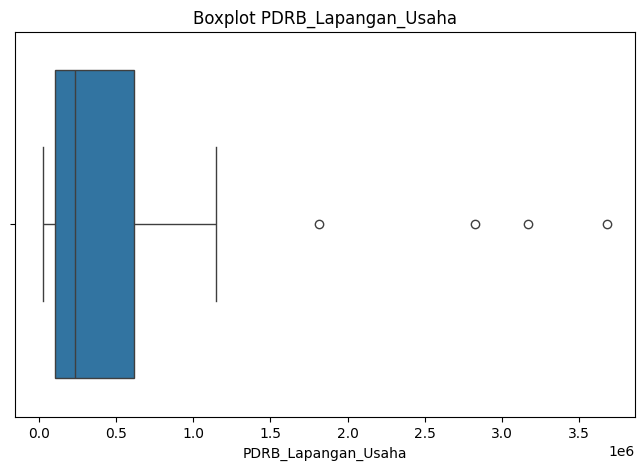

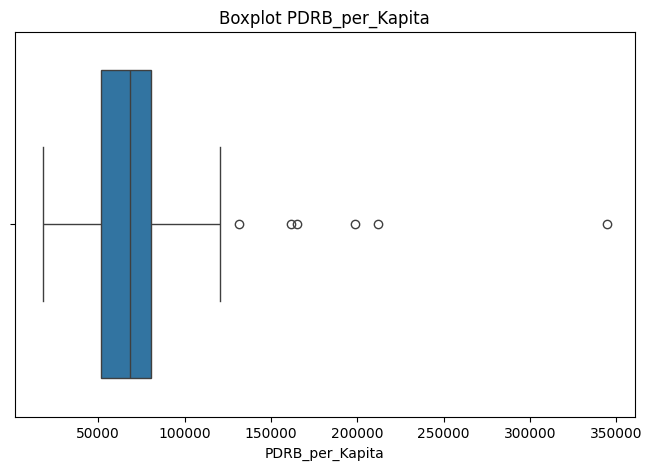

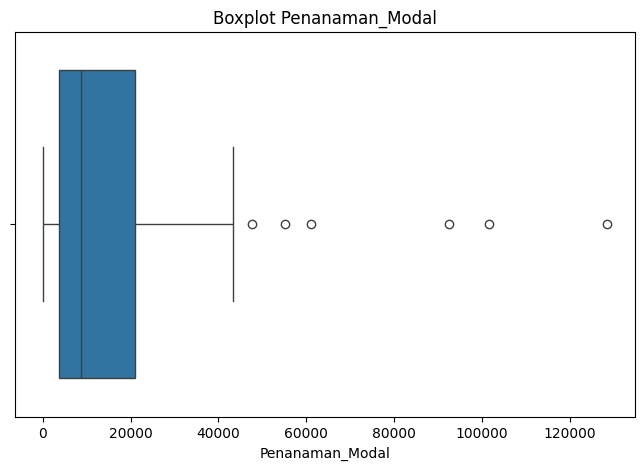

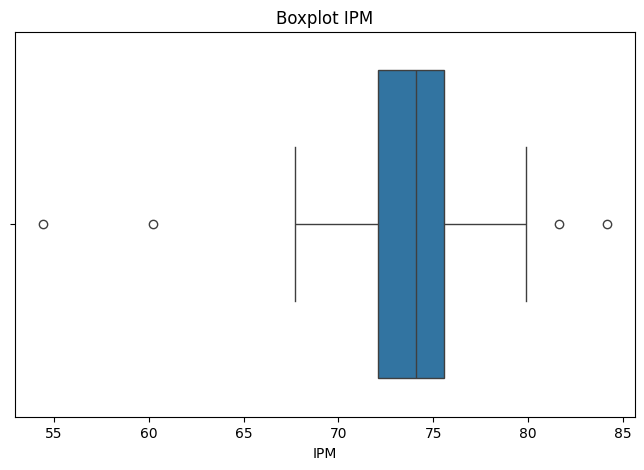

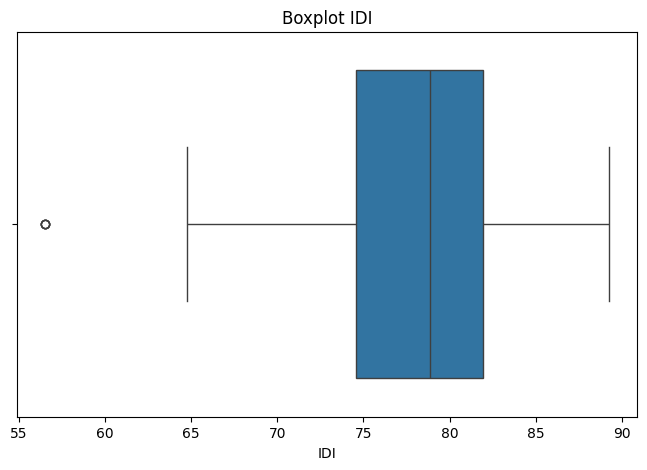

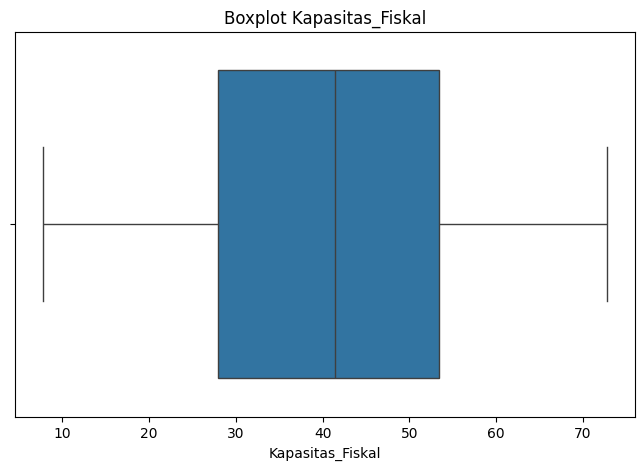

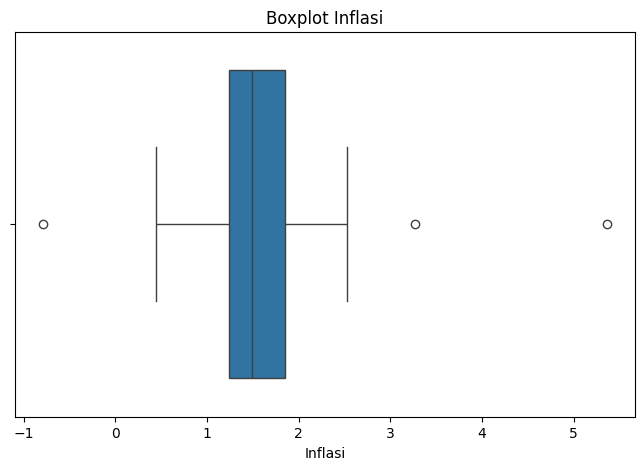

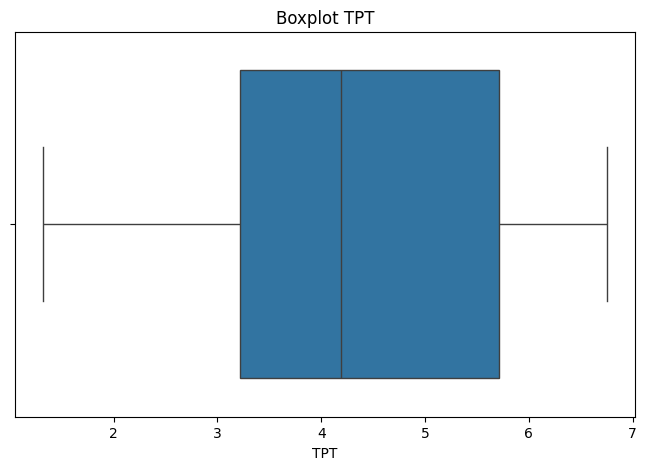

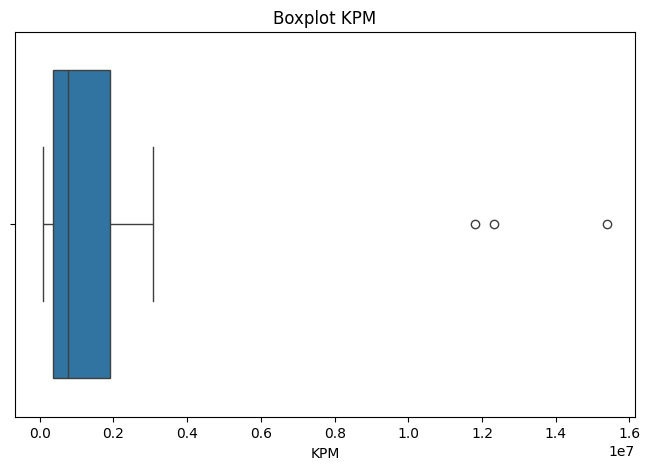

In [8]:
for col in variabel_deskriptif:

    plt.figure()

    sns.boxplot(x=df_index[col])

    plt.title(f"Boxplot {col}")

    plt.show()

## **Transformasi Log Pembentuk Indeks**

In [9]:
# Dilakukan hanya untuk variabel yang sangat skewed

variabel_log_index = [

    "PDRB_Lapangan_Usaha",
    "PDRB_per_Kapita",
    "Penanaman_Modal",
    "Kapasitas_Fiskal",
    "KPM"

]

for col in variabel_log_index:

    if col in df_index.columns:

        df_index[col] = np.log1p(df_index[col])

print("\n=================================================")
print("HASIL LOG TRANSFORM PEMBENTUK INDEKS")
print("=================================================")

print(df_index[variabel_log_index].head())


HASIL LOG TRANSFORM PEMBENTUK INDEKS
   PDRB_Lapangan_Usaha  PDRB_per_Kapita  Penanaman_Modal  Kapasitas_Fiskal  \
0            12.401652        10.687006         9.026177          3.377929   
1            13.952592        11.206069        10.018899          4.037245   
2            12.716339        10.952281         8.981845          3.837084   
3            13.922105        12.015824        11.020244          4.063542   
4            12.685949        11.371084         9.209060          3.811318   

         KPM  
0  14.474488  
1  14.938555  
2  14.057390  
3  13.866596  
4  13.436634  


## **Normalisasi Min Max**

In [10]:
df_norm = pd.DataFrame()

df_norm["Provinsi"] = df_index["Provinsi"]


# variabel positif
for col in variabel_positif:

    df_norm[col] = (

        (df_index[col] - df_index[col].min()) /

        (df_index[col].max() - df_index[col].min())

    )


# variabel negatif
for col in variabel_negatif:

    df_norm[col] = (

        (df_index[col].max() - df_index[col]) /

        (df_index[col].max() - df_index[col].min())

    )

## **Agregasi Sederhana**

In [11]:
df_norm["IRE"] = df_norm[
    variabel_positif + variabel_negatif
].mean(axis=1)

print("\n=================================================")
print("HASIL INDEKS RESILIENSI EKONOMI")
print("=================================================")

print(df_norm[["Provinsi","IRE"]])


HASIL INDEKS RESILIENSI EKONOMI
                Provinsi       IRE
0                   Aceh  0.482349
1         Sumatera Utara  0.596675
2         Sumatera Barat  0.569150
3                   Riau  0.709796
4                  Jambi  0.619923
5       Sumatera Selatan  0.650096
6               Bengkulu  0.592743
7                Lampung  0.550628
8   Kep. Bangka Belitung  0.624984
9              Kep. Riau  0.639056
10           DKI Jakarta  0.794434
11            Jawa Barat  0.596733
12           Jawa Tengah  0.613433
13         DI Yogyakarta  0.629884
14            Jawa Timur  0.673760
15                Banten  0.594339
16                  Bali  0.713908
17   Nusa Tenggara Barat  0.588632
18   Nusa Tenggara Timur  0.491323
19      Kalimantan Barat  0.591180
20     Kalimantan Tengah  0.618399
21    Kalimantan Selatan  0.616285
22      Kalimantan Timur  0.717200
23      Kalimantan Utara  0.654359
24        Sulawesi Utara  0.587078
25       Sulawesi Tengah  0.628384
26      Sulawesi Selat

## **Ranking Indeks**

In [12]:
df_norm["Ranking"] = df_norm["IRE"].rank(
    ascending=False,
    method="min"
)

hasil_index = df_norm[
    ["Provinsi","IRE","Ranking"]
].sort_values(
    by="IRE",
    ascending=False
)

print("\n=================================================")
print("RANKING INDEKS RESILIENSI EKONOMI")
print("=================================================")

print(hasil_index)


RANKING INDEKS RESILIENSI EKONOMI
                Provinsi       IRE  Ranking
10           DKI Jakarta  0.794434      1.0
22      Kalimantan Timur  0.717200      2.0
16                  Bali  0.713908      3.0
3                   Riau  0.709796      4.0
14            Jawa Timur  0.673760      5.0
23      Kalimantan Utara  0.654359      6.0
5       Sumatera Selatan  0.650096      7.0
9              Kep. Riau  0.639056      8.0
13         DI Yogyakarta  0.629884      9.0
25       Sulawesi Tengah  0.628384     10.0
8   Kep. Bangka Belitung  0.624984     11.0
4                  Jambi  0.619923     12.0
20     Kalimantan Tengah  0.618399     13.0
21    Kalimantan Selatan  0.616285     14.0
12           Jawa Tengah  0.613433     15.0
26      Sulawesi Selatan  0.612585     16.0
11            Jawa Barat  0.596733     17.0
1         Sumatera Utara  0.596675     18.0
15                Banten  0.594339     19.0
6               Bengkulu  0.592743     20.0
27     Sulawesi Tenggara  0.592192     21

## **Visualisasi Indeks**

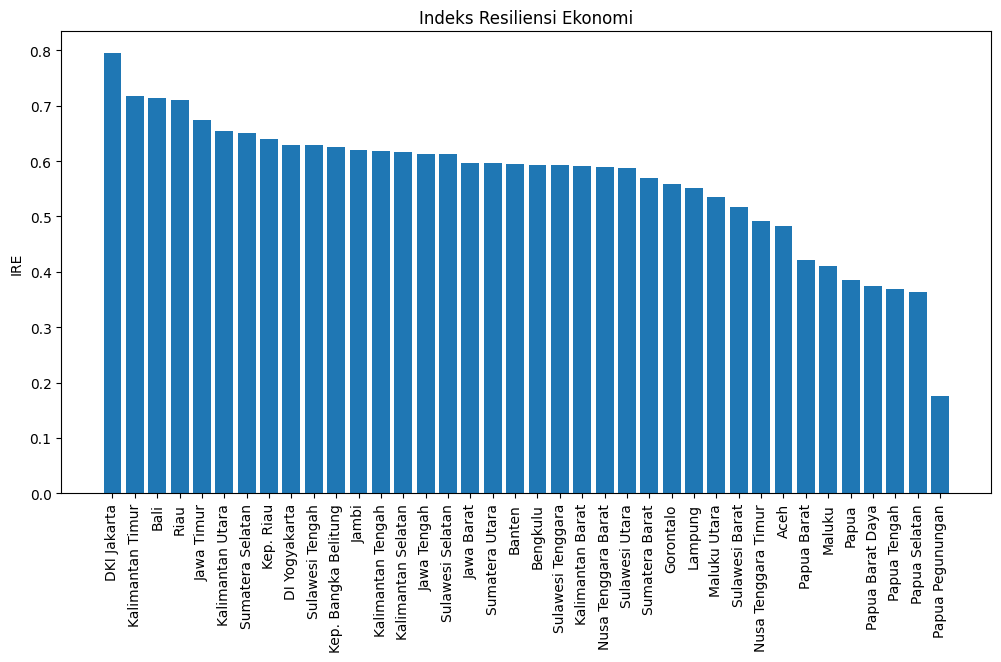

In [13]:
plt.figure(figsize=(12,6))

plt.bar(
    hasil_index["Provinsi"],
    hasil_index["IRE"]
)

plt.xticks(rotation=90)

plt.ylabel("IRE")

plt.title("Indeks Resiliensi Ekonomi")

plt.show()

## **Baca Data Pemodelan Indeks**

In [14]:
# File ini berisi variabel khusus untuk model spline

df_model = pd.read_excel("/content/prediktor_model_spline.xlsx")

print(df_model.head())

         Provinsi  Gini_Ratio  Penduduk_Miskin   TPAK  Pengguna_Internet
0            Aceh       0.294            14.23  65.11              62.93
1  Sumatera Utara       0.306             7.99  71.36              74.15
2  Sumatera Barat       0.287             5.97  70.28              74.59
3            Riau       0.306             6.67  66.33              77.68
4           Jambi       0.315             7.10  68.87              71.76


## **Cek Nama Kolom Data Pemodelan**

In [15]:
print("\nKOLOM DATA PEMODELAN")
print(df_model.columns.tolist())


KOLOM DATA PEMODELAN
['Provinsi', 'Gini_Ratio', 'Penduduk_Miskin', 'TPAK', 'Pengguna_Internet']


## **Gabung Data IRE dengan Data Pemodelan**

In [16]:
df_model = pd.merge(

    df_norm[["Provinsi","IRE"]],

    df_model,

    on="Provinsi"

)

df_model.rename(columns={
    "IRE":"Y"
}, inplace=True)

## **Variabel Prediktor Model Spline**

In [17]:
prediktor = [

    "Gini_Ratio",
    "Penduduk_Miskin",
    "TPAK",
    "Pengguna_Internet"

]

## **Scatterplot IRE vs Prediktor**

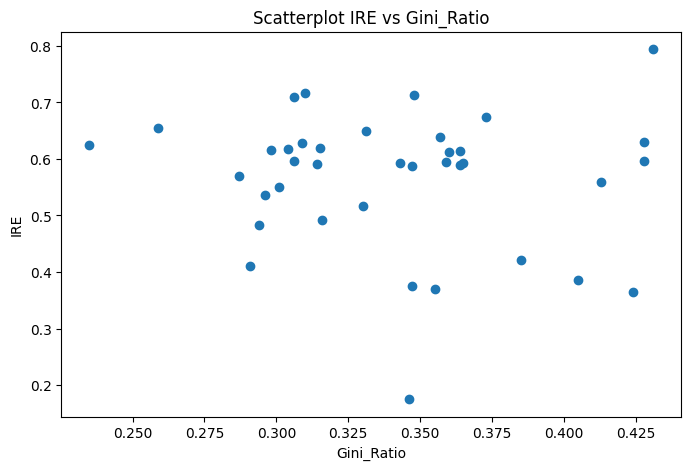

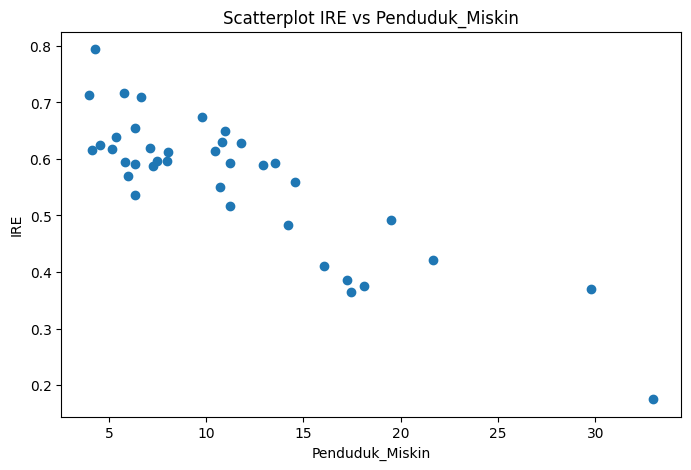

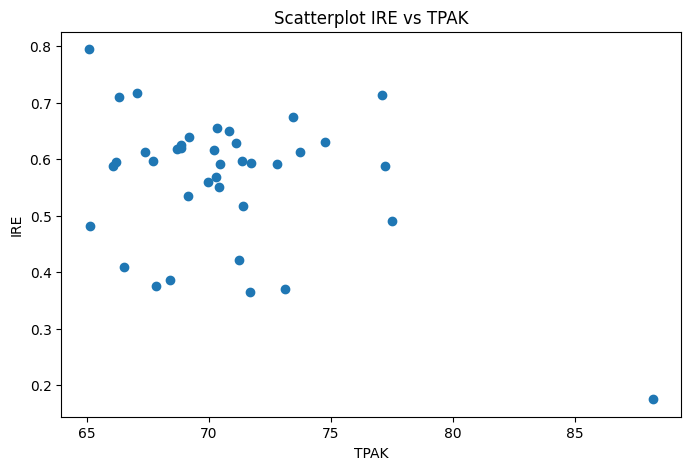

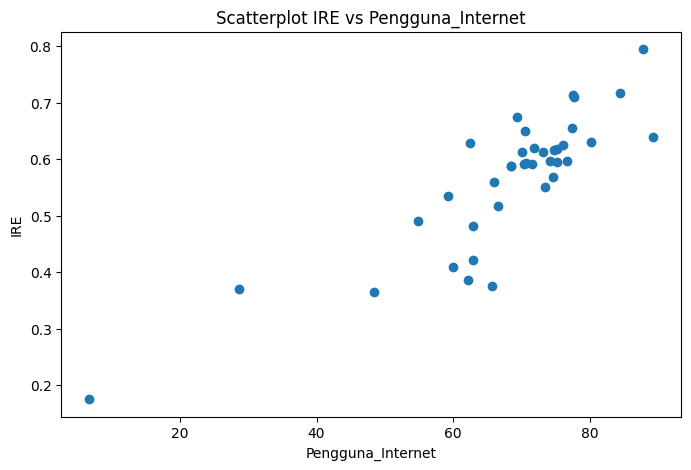

In [18]:
for col in prediktor:

    plt.figure()

    plt.scatter(
        df_model[col],
        df_model["Y"]
    )

    plt.xlabel(col)

    plt.ylabel("IRE")

    plt.title(f"Scatterplot IRE vs {col}")

    plt.show()

## **Transformasi Log Variabel Pemodelan**

In [19]:
# hanya variabel yang skewed

variabel_log_model = [

    "Penduduk_Miskin"

]

for col in variabel_log_model:

    if col in df_model.columns:

        df_model[col] = np.log1p(df_model[col])

print("\n=================================================")
print("HASIL LOG TRANSFORM PEMODELAN")
print("=================================================")

print(df_model[variabel_log_model].head())


HASIL LOG TRANSFORM PEMODELAN
   Penduduk_Miskin
0         2.723267
1         2.196113
2         1.941615
3         2.037317
4         2.091864


## **Fungsi Spline Truncated**

In [20]:
# =========================================================
# FUNGSI SPLINE TRUNCATED
# =========================================================

def truncated(x, knot):

    return np.maximum(0, x-knot)

## **Membangun Design Matrix**

In [21]:
# =========================================================
# MEMBANGUN DESIGN MATRIX
# =========================================================

def build_design_matrix(df, kandidat_knot):

    X = pd.DataFrame(index=df.index)

    # --------------------------------------------
    # Komponen Linear
    # --------------------------------------------

    for col in prediktor:

        X[col] = df[col]

    # --------------------------------------------
    # Komponen Spline
    # --------------------------------------------

    for col in prediktor:

        for k in kandidat_knot[col]:

            X[f"{col}_K{k:.4f}"] = truncated(

                df[col],

                k

            )

    # --------------------------------------------
    # Konstanta
    # --------------------------------------------

    X = sm.add_constant(X)

    return X

## **Pemilihan Kandidat Knot**

In [22]:
# =========================================================
# PEMILIHAN KANDIDAT TITIK KNOT
# =========================================================

def kandidat_knot(df, jumlah_knot):

    kandidat = {}

    probs = np.linspace(

        0.25,

        0.75,

        jumlah_knot

    )

    for col in prediktor:

        kandidat[col] = list(

            df[col].quantile(probs)

        )

    return kandidat

## **Menampilkan Kandidat Knot**

In [23]:
# =========================================================
# MENAMPILKAN KANDIDAT KNOT
# =========================================================

jumlah_knot = 1

kandidat = kandidat_knot(

    df_model,

    jumlah_knot

)

print("\n=================================================")

print("KANDIDAT TITIK KNOT")

print("=================================================")

for col in prediktor:

    print(col)

    print(np.round(kandidat[col],4))

    print()


KANDIDAT TITIK KNOT
Gini_Ratio
[0.306]

Penduduk_Miskin
[1.9906]

TPAK
[67.9575]

Pengguna_Internet
[63.6575]



## **Fit Model Spline**

In [24]:
# =========================================================
# FIT MODEL SPLINE
# =========================================================

def fit_model(df, kandidat):

    # --------------------------------------------
    # Design Matrix
    # --------------------------------------------

    X = build_design_matrix(

        df,

        kandidat

    )

    # --------------------------------------------
    # Variabel Respon
    # --------------------------------------------

    y = df["Y"]

    # --------------------------------------------
    # Estimasi Parameter
    # --------------------------------------------

    model = sm.OLS(

        y,

        X

    ).fit()

    # --------------------------------------------
    # Prediksi
    # --------------------------------------------

    yhat = model.predict(X)

    resid = y-yhat

    # --------------------------------------------
    # Menghitung GCV
    # --------------------------------------------

    n = len(y)

    p = X.shape[1]

    sse = np.sum(

        resid**2

    )

    mse = sse/n

    gcv = mse / (

        (1-p/n)**2

    )

    return (

        model,

        yhat,

        resid,

        sse,

        gcv

    )

## **Pemilihan Titik Knot Optimum**

In [25]:
# =========================================================
# PEMILIHAN TITIK KNOT OPTIMUM
# =========================================================

hasil_gcv = []

# =========================================================
# 1 TITIK KNOT
# =========================================================

knot_1 = kandidat_knot(

    df_model,

    1

)

model_1, yhat_1, resid_1, sse_1, gcv_1 = fit_model(

    df_model,

    knot_1

)

hasil_gcv.append([

    "Satu Titik Knot",

    gcv_1

])

# =========================================================
# 2 TITIK KNOT
# =========================================================

knot_2 = kandidat_knot(

    df_model,

    2

)

model_2, yhat_2, resid_2, sse_2, gcv_2 = fit_model(

    df_model,

    knot_2

)

hasil_gcv.append([

    "Dua Titik Knot",

    gcv_2

])


# =========================================================
# 3 TITIK KNOT
# =========================================================

knot_3 = kandidat_knot(

    df_model,

    3

)

model_3, yhat_3, resid_3, sse_3, gcv_3 = fit_model(

    df_model,

    knot_3

)

hasil_gcv.append([

    "Tiga Titik Knot",

    gcv_3

])

## **Tabel GCV**

In [26]:
# =========================================================
# TABEL GCV
# =========================================================

tabel_gcv = pd.DataFrame(

    hasil_gcv,

    columns=[

        "Model",

        "GCV"

    ]

)

print("\n=================================================")

print("PERBANDINGAN NILAI GCV")

print("=================================================")

print(tabel_gcv)


PERBANDINGAN NILAI GCV
             Model       GCV
0  Satu Titik Knot  0.004311
1   Dua Titik Knot  0.004714
2  Tiga Titik Knot  0.005528


## **Memilih Model Terbaik**

In [27]:
# =========================================================
# MEMILIH MODEL TERBAIK
# =========================================================

if gcv_1 < gcv_2:

    model_best = model_1

    yhat = yhat_1

    resid = resid_1

    sse = sse_1

    gcv_best = gcv_1

    knot_terbaik = knot_1

    jumlah_knot = 1

else:

    model_best = model_2

    yhat = yhat_2

    resid = resid_2

    sse = sse_2

    gcv_best = gcv_2

    knot_terbaik = knot_2

    jumlah_knot = 2

## **Menampilkan Titik Knot Terbaik**

In [28]:
# =========================================================
# TITIK KNOT OPTIMUM
# =========================================================

print("\n=================================================")

print("TITIK KNOT OPTIMUM")

print("=================================================")

print("Jumlah Knot :", jumlah_knot)

print()

for col in prediktor:

    print(col)

    print(np.round(knot_terbaik[col],4))

    print()


TITIK KNOT OPTIMUM
Jumlah Knot : 1

Gini_Ratio
[0.306]

Penduduk_Miskin
[1.9906]

TPAK
[67.9575]

Pengguna_Internet
[63.6575]



## **Estimasi Parameter Model**

In [29]:
# =========================================================
# ESTIMASI PARAMETER MODEL
# =========================================================

print("\n=================================================")

print("ESTIMASI PARAMETER MODEL")

print("=================================================")

print(model_best.summary())


ESTIMASI PARAMETER MODEL
                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.824
Model:                            OLS   Adj. R-squared:                  0.775
Method:                 Least Squares   F-statistic:                     16.94
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           5.12e-09
Time:                        05:58:37   Log-Likelihood:                 59.836
No. Observations:                  38   AIC:                            -101.7
Df Residuals:                      29   BIC:                            -86.93
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------

## **Uji Serentak (ANOVA)**

In [30]:
# =========================================================
# UJI SERENTAK (ANOVA)
# =========================================================

anova_serentak = pd.DataFrame({

    "Sumber Variasi":[

        "Regresi",

        "Error",

        "Total"

    ],

    "Derajat Bebas":[

        model_best.df_model,

        model_best.df_resid,

        model_best.df_model + model_best.df_resid

    ],

    "Jumlah Kuadrat":[

        model_best.ess,

        model_best.ssr,

        model_best.centered_tss

    ],

    "Kuadrat Tengah":[

        model_best.mse_model,

        model_best.mse_resid,

        ""

    ],

    "F Hitung":[

        model_best.fvalue,

        "",

        ""

    ],

    "p-value":[

        model_best.f_pvalue,

        "",

        ""

    ]

})

print("\n=================================================")

print("ANOVA UJI SERENTAK")

print("=================================================")

print(anova_serentak)


ANOVA UJI SERENTAK
  Sumber Variasi  Derajat Bebas  Jumlah Kuadrat Kuadrat Tengah   F Hitung  \
0        Regresi            8.0        0.445740       0.055717  16.935239   
1          Error           29.0        0.095411        0.00329              
2          Total           37.0        0.541150                             

  p-value  
0     0.0  
1          
2          


## **Uji Parsial**

In [31]:
# =========================================================
# UJI PARSIAL
# =========================================================

uji_parsial = pd.DataFrame({

    "Koef":

    model_best.params,

    "t hitung":

    model_best.tvalues,

    "p value":

    model_best.pvalues

})

print("\n=================================================")

print("UJI PARSIAL")

print("=================================================")

print(uji_parsial)


UJI PARSIAL
                                Koef  t hitung   p value
const                       1.065027  1.133504  0.266287
Gini_Ratio                  0.534586  0.698336  0.490530
Penduduk_Miskin            -0.008156 -0.073922  0.941580
TPAK                       -0.014595 -1.082498  0.287951
Pengguna_Internet           0.005392  3.831195  0.000631
Gini_Ratio_K0.3060         -0.559878 -0.632521  0.532002
Penduduk_Miskin_K1.9906    -0.107615 -0.855114  0.399498
TPAK_K67.9575               0.022516  1.451411  0.157398
Pengguna_Internet_K63.6575 -0.000010 -0.003813  0.996983


## **Kriteria Model Terbaik**

In [32]:
# =========================================================
# KRITERIA MODEL TERBAIK
# =========================================================

print("\n=================================================")

print("KRITERIA MODEL TERBAIK")

print("=================================================")

print("Jumlah Knot :", jumlah_knot)

print()

print("R2       :", model_best.rsquared)

print("Adj R2   :", model_best.rsquared_adj)

print("SSE      :", sse)

print("GCV      :", gcv_best)


KRITERIA MODEL TERBAIK
Jumlah Knot : 1

R2       : 0.8236888157874979
Adj R2   : 0.7750512477288766
SSE      : 0.09541087934282592
GCV      : 0.004311074215252539


## **Visualisasi Fitting**

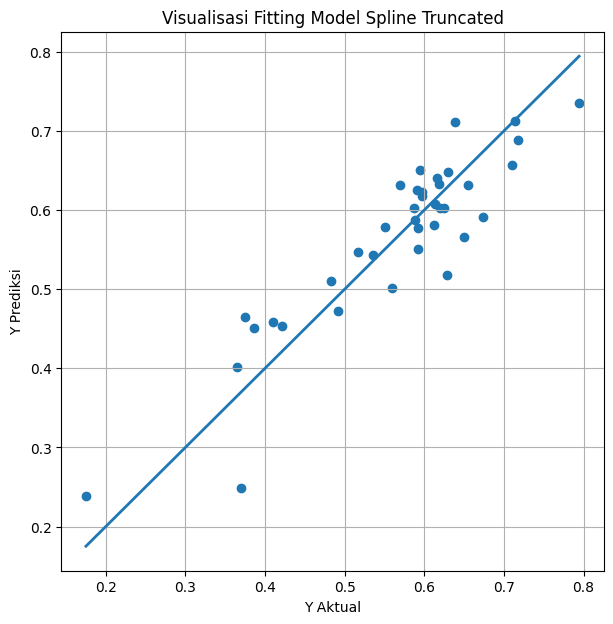

In [33]:
# =========================================================
# VISUALISASI FITTING MODEL
# =========================================================

plt.figure(figsize=(7,7))

plt.scatter(

    df_model["Y"],

    yhat

)

plt.plot(

    [

        df_model["Y"].min(),

        df_model["Y"].max()

    ],

    [

        df_model["Y"].min(),

        df_model["Y"].max()

    ],

    linewidth=2

)

plt.xlabel("Y Aktual")

plt.ylabel("Y Prediksi")

plt.title("Visualisasi Fitting Model Spline Truncated")

plt.grid(True)

plt.show()

## **Uji Glejser (Heteroskedastisitas)**

In [34]:
# =========================================================
# UJI GLEJSER
# =========================================================

abs_resid = np.abs(resid)

X_glejser = build_design_matrix(

    df_model,

    knot_terbaik

)

model_glejser = sm.OLS(

    abs_resid,

    X_glejser

).fit()

n = len(abs_resid)

p = X_glejser.shape[1]-1

SSR = np.sum(

    (

        model_glejser.fittedvalues -

        abs_resid.mean()

    )**2

)

SSE = np.sum(

    model_glejser.resid**2

)

SST = SSR + SSE

MSR = SSR/p

MSE = SSE/(n-p-1)

F_hitung = MSR/MSE

p_value = 1-f.cdf(

    F_hitung,

    p,

    n-p-1

)

## **Tabel Anova Glejser**

In [35]:
# =========================================================
# ANOVA UJI GLEJSER
# =========================================================

anova_glejser = pd.DataFrame({

    "Sumber Variasi":[

        "Regresi",

        "Error",

        "Total"

    ],

    "Derajat Bebas":[

        p,

        n-p-1,

        n-1

    ],

    "Jumlah Kuadrat":[

        SSR,

        SSE,

        SST

    ],

    "Kuadrat Tengah":[

        MSR,

        MSE,

        ""

    ],

    "F Hitung":[

        F_hitung,

        "",

        ""

    ],

    "p-value":[

        p_value,

        "",

        ""

    ]

})

print("\n=================================================")

print("ANOVA UJI GLEJSER")

print("=================================================")

print(anova_glejser)


ANOVA UJI GLEJSER
  Sumber Variasi  Derajat Bebas  Jumlah Kuadrat Kuadrat Tengah  F Hitung  \
0        Regresi              8        0.011996         0.0015  2.126234   
1          Error             29        0.020452       0.000705             
2          Total             37        0.032448                            

   p-value  
0  0.06566  
1           
2           


## **Run Test**

In [36]:
# =========================================================
# RUN TEST MANUAL
# =========================================================

tanda = np.where(

    resid>=0,

    1,

    0

)

n1 = np.sum(

    tanda==1

)

n2 = np.sum(

    tanda==0

)

r = 1

for i in range(

    1,

    len(tanda)

):

    if tanda[i] != tanda[i-1]:

        r += 1

mean_r = (

    (2*n1*n2)/(n1+n2)

) + 1

std_r = np.sqrt(

(

2*n1*n2*

(

2*n1*n2-n1-n2

)

)

/

(

(

n1+n2

)**2

*

(

n1+n2-1

)

)

)

z_alpha = 1.96

r_bawah = mean_r-z_alpha*std_r

r_atas = mean_r+z_alpha*std_r

## **Tabel Run Test**

In [37]:
# =========================================================
# PERHITUNGAN RUN TEST
# =========================================================

run_table = pd.DataFrame({

    "r":[r],

    "n1":[n1],

    "n2":[n2],

    "ratas":[round(r_atas)],

    "rbawah":[round(r_bawah)]

})

print("\n=================================================")

print("PERHITUNGAN RUN TEST")

print("=================================================")

print(run_table)


PERHITUNGAN RUN TEST
    r  n1  n2  ratas  rbawah
0  19  18  20     26      14


## **Normalitas Uji Kolmogrov Smirnov**

In [38]:
# =========================================================
# UJI KOLMOGOROV SMIRNOV
# =========================================================

resid_std = (

(

resid -

np.mean(resid)

)

/

np.std(

resid,

ddof=1

)

)

ks_stat, ks_p = kstest(

    resid_std,

    "norm"

)

print("\n=================================================")

print("UJI KOLMOGOROV SMIRNOV")

print("=================================================")

print("KS Statistik :",ks_stat)

print("p-value      :",ks_p)


UJI KOLMOGOROV SMIRNOV
KS Statistik : 0.10817784105340345
p-value      : 0.7250140295238297
